# Can the makeover and the guesstimate carry the slide?

**Week 4, Tuesday, the morning's one notebook.** The city head asked for the redesign on
one slide. Yesterday's notebooks counted the ratio on twelve rows and on 6,360 driver-weeks.
This notebook does two things, in the order the morning takes them.

**First, the makeover.** The twelve-week Monday series read three ways (per peak online
hour, per driver-week, per trip) is drawn cluttered as the Monday operations analyst sent
it, then cleared to one claim with one chart, one caveat and one action.

**Second, the ledger.** The city head's afternoon question (how many drivers must be
online at the evening peak) is sized with the four steps of a guesstimate, every assumption
written down as a row of a ledger, the product computed, and the number validated against
the case's own data and a published figure where one exists.

> *Illustrative case: Uber in Hyderabad. The company is real. The data is synthetic, built
> for this class.*


## What does the notebook load, and where does the data live?

The first cell finds the shared helper `c2kit` and loads Tuesday's two case tables plus
Monday's weekly series through Tuesday's facts file. Every number in this notebook comes
from those files; nothing is typed in. Run this cell again after any kernel restart.


In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
import matplotlib.pyplot as plt
import yaml

twelve = pd.read_csv("../data/C2_W04_D02_twelve_rows_STUDENT.csv")
weekly = pd.read_csv("../data/C2_W04_D02_three_denominators_STUDENT.csv")
with open("../internal/C2_W04_D02_facts_INTERNAL.yaml") as f:
    facts = yaml.safe_load(f)
by_id = {n["id"]: n["value"] for n in facts["numbers"]}

print(f"twelve rows: {len(twelve)}; weekly series: {len(weekly)} weeks; "
      f"facts loaded: {len(by_id)} numbers")


twelve rows: 12; weekly series: 12 weeks; facts loaded: 47 numbers


## Where does this notebook sit on the day's ladder?


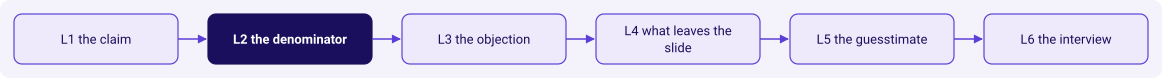

In [2]:
kit.flow(["L1 the claim", "L2 the denominator", "L3 the objection",
          "L4 what leaves the slide", "L5 the guesstimate", "L6 the interview"], lit=1)


## What do the twelve rows say when they are read in rupees three ways?

Yesterday the twelve rows said hours up, trips down, trips per peak online hour nearly
halved. Today the same rows say rupees three ways, and the three answers disagree.

**Predict first.** Among the three denominators (per peak online hour, per driver-week,
per trip), which falls most? Letters:

- a) Per peak online hour falls most; per trip holds
- b) Per driver-week falls most; per trip rises
- c) All three fall by about the same amount
- d) Per trip falls most; per driver-week holds

**Write your letter.** The next cell counts the four totals and reads the three numbers.


In [3]:
before = twelve[twelve.window == "before"]
after = twelve[twelve.window == "after"]

totals = pd.DataFrame({
    "window": ["before", "after"],
    "hours":        [before.peak_online_hours.sum(), after.peak_online_hours.sum()],
    "driver_weeks": [len(before), len(after)],
    "trips":        [before.peak_trips.sum(), after.peak_trips.sum()],
    "bookings_rs":  [before.peak_bookings_rs.sum(), after.peak_bookings_rs.sum()],
})
totals["rs_per_hour"]        = (totals.bookings_rs / totals.hours).round(2)
totals["rs_per_driver_week"] = (totals.bookings_rs / totals.driver_weeks).round(2)
totals["rs_per_trip"]        = (totals.bookings_rs / totals.trips).round(2)
totals


,window,hours,driver_weeks,trips,bookings_rs,rs_per_hour,rs_per_driver_week,rs_per_trip
0,before,60,6,114,18810,313.50,3135.0,165.0
1,after,74,6,88,14520,196.22,2420.0,165.0


**Three denominators, three sentences.** Per peak online hour: Rs 313.5 to Rs 196.2,
down 37 percent. Per driver-week: Rs 3,135 to Rs 2,420, down 23 percent (the twelve rows
have the same six drivers both weeks, so the denominator does not move). Per trip: Rs 165
flat (because a trip pays its fare).

**The predict reveal.** Letter (a) is right on the twelve rows. The city head's slide, on
the full data, will tell a slightly different story because the denominator per
driver-week moves there; the room sees that two cells down.


In [4]:
kit.check("per-hour before matches the facts file: Rs 313.5",
          round(totals.loc[totals.window == "before", "rs_per_hour"].iloc[0], 1)
          == by_id["twelve_rs_per_hour_before"])
kit.check("per-hour after matches the facts file: Rs 196.2",
          round(totals.loc[totals.window == "after", "rs_per_hour"].iloc[0], 1)
          == by_id["twelve_rs_per_hour_after"])
kit.check("per-trip is flat at Rs 165 (bookings / trips)",
          totals.rs_per_trip.nunique() == 1 and totals.rs_per_trip.iloc[0] == 165.0)


## What do the three denominators do over all 6,360 and 6,500 driver-weeks?

The twelve-row totals carry the shape of the three stories, but the slide's number lives
on the full data, which Monday's weekly series holds. The next cell reads it from Tuesday's
twelve-week table and groups it into the two windows.


In [5]:
full = weekly.groupby("window", sort=False).agg(
    hours=("hours", "sum"),
    trips=("trips", "sum"),
    driver_weeks=("driver_weeks", "sum"),
    bookings_rs=("bookings_rs", "sum"),
).reset_index()
# Reorder so 'before' prints before 'after'
full = full.set_index("window").loc[["before", "after"]].reset_index()
full["rs_per_hour"] = (full.bookings_rs / full.hours).round(2)
full["rs_per_driver_week"] = (full.bookings_rs / full.driver_weeks).round(2)
full["rs_per_trip"] = (full.bookings_rs / full.trips).round(2)
full


,window,hours,trips,driver_weeks,bookings_rs,rs_per_hour,rs_per_driver_week,rs_per_trip
0,before,118000,224200,6360,36993000,313.50,5816.51,165.0
1,after,146300,230900,6500,38098500,260.41,5861.31,165.0


**On the full data, three different directions.** Per peak online hour: Rs 313.50
to Rs 260.42, down 17 percent (the finance partner's opening number). Per driver-week:
Rs 5,816.50 to Rs 5,861.31, up less than one percent (what the marketing lead will quote).
Per trip: Rs 165 flat (what finance will ask about last, because a trip pays its fare).

**The reason the three disagree.** Hours went up by more than bookings fell, so the
per-hour read is a sharp fall. Driver-weeks and bookings both rose by about the same
amount, so the per-driver-week read is nearly flat. Trips earn Rs 165 each either way, so
the per-trip read holds.


In [6]:
kit.check("full-data per-hour before == 313.5 (Monday's number)",
          round(full.loc[full.window == "before", "rs_per_hour"].iloc[0], 1) == 313.5)
kit.check("full-data per-hour after ~ 260 (Monday's number)",
          abs(full.loc[full.window == "after", "rs_per_hour"].iloc[0] - 260.4) < 0.5)
kit.check("full-data per-driver-week rises slightly (less than 1 percent)",
          0 < (full.loc[full.window == "after", "rs_per_driver_week"].iloc[0]
               / full.loc[full.window == "before", "rs_per_driver_week"].iloc[0] - 1) < 0.01)


## What does the cluttered slide look like in matplotlib?

Monday's operations analyst drew the twelve weeks on one chart with three lines (per hour,
per driver-week, per trip). Three different units on three different axes is the
cluttered picture every room has seen; the next cell builds it, so the slide the morning
rebuilds is one the room has drawn themselves.


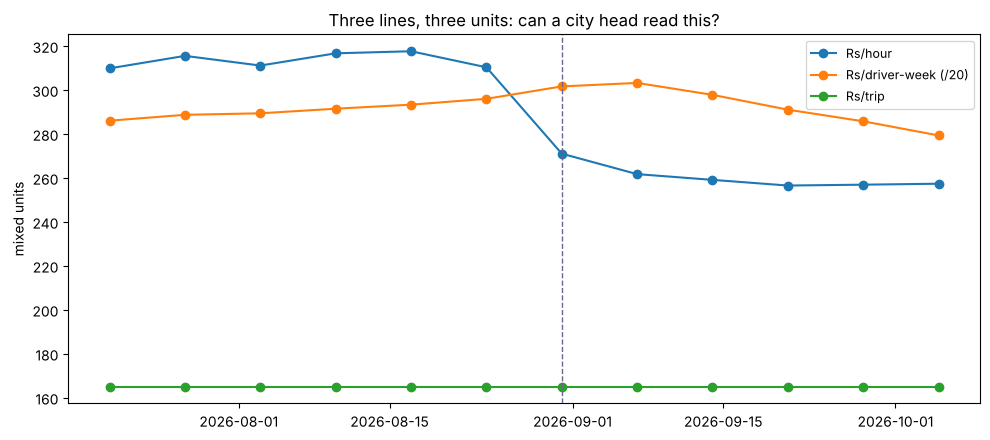

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
weekly["week"] = pd.to_datetime(weekly.week_start)
colours = {"before": "#5B3FD6", "after": "#D63A6A"}
for unit, scale, label in [("rs_per_hour", 1, "Rs/hour"),
                            ("rs_per_driver_week", 1/20, "Rs/driver-week (/20)"),
                            ("rs_per_trip", 1, "Rs/trip")]:
    ax.plot(weekly.week, weekly[unit] * scale, marker="o", label=label)
ax.axvline(weekly[weekly.window == "after"].week.iloc[0], color="#6B6690",
           linestyle="--", linewidth=1)
ax.set_title("Three lines, three units: can a city head read this?")
ax.set_ylabel("mixed units")
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()


## What does the slide look like when it reads one claim?

The declutter is: one chart, one denominator, the caveat beside it, the action at the
foot. The denominator is per peak online hour, because the scheme pays per peak online
hour. The chart is a bar pair, not a line, because the slide carries one number not a
series.


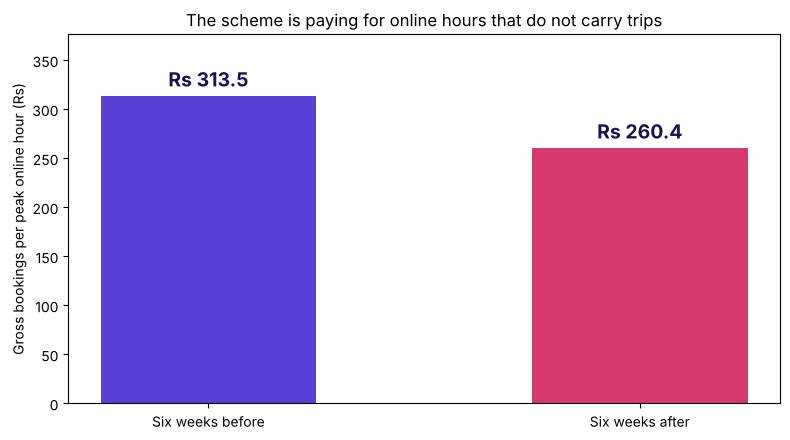

In [8]:
rs_before = by_id["full_rs_per_hour_before"]
rs_after = by_id["full_rs_per_hour_after"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(["Six weeks before", "Six weeks after"], [rs_before, rs_after],
              color=["#5B3FD6", "#D63A6A"], edgecolor="none", width=0.5)
for bar, v in zip(bars, [rs_before, rs_after]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 5, f"Rs {v}",
            ha="center", va="bottom", fontsize=14, fontweight="bold", color="#1A0F5C")
ax.set_ylim(0, max(rs_before, rs_after) * 1.2)
ax.set_ylabel("Gross bookings per peak online hour (Rs)")
ax.set_title("The scheme is paying for online hours that do not carry trips")
plt.tight_layout()
plt.show()


## What does the guesstimate ledger look like, with every assumption written?

The afternoon dojo sizes drivers online at the evening peak. Four steps: clarify, map,
calculate, validate. The ledger below is the map step as a table, so every assumption
sits beside its value, its unit and whether it is a case fact, a public fact or an
assumption with a range.


In [9]:
ledger = pd.DataFrame([
    {"factor": "Peak requests per hour",       "value": by_id["hyd_peak_requests_per_hour_mid"],
     "unit": "requests/hour", "kind": "assumption",
     "note": "range 7,000 to 12,000; the number the demand hangs on"},
    {"factor": "Trips per driver per hour",     "value": by_id["trips_per_driver_per_peak_hour"],
     "unit": "trips/driver/hour", "kind": "case-anchored",
     "note": "from Monday's trips per peak online hour of 1.6 to 1.9"},
    {"factor": "Idle share",                    "value": by_id["idle_share_assumption"],
     "unit": "share",             "kind": "assumption",
     "note": "range 0.20 to 0.40; the number that moves the answer most"},
    {"factor": "Buffer (wait target)",          "value": by_id["buffer_for_wait"],
     "unit": "multiplier",        "kind": "assumption",
     "note": "15 percent above drivers needed, for median wait under five minutes"},
])
ledger


,factor,value,unit,kind,note
0,Peak requests per hour,10000.00,requests/hour,assumption,"range 7,000 to 12,000; the number the demand h..."
1,Trips per driver per hour,2.00,trips/driver/hour,case-anchored,from Monday's trips per peak online hour of 1....
2,Idle share,0.30,share,assumption,range 0.20 to 0.40; the number that moves the ...
3,Buffer (wait target),1.15,multiplier,assumption,"15 percent above drivers needed, for median wa..."


## What does the calculation step reach, said aloud?

**Step 1.** 10,000 requests per hour divided by 2 trips per driver per hour is 5,000
driver-hours of demand each hour. **Step 2.** Only 70 percent of online drivers are on a
trip at any moment, so divide by 0.70 to get drivers needed online: about 7,143. **Step 3.**
Multiply by 1.15 for the wait buffer: about 8,214, rounded to about 8,200. **The range.**
Lower bound: 7,000 requests, 20 percent idle, same buffer, about 5,000 drivers. Upper
bound: 12,000 requests, 40 percent idle, same buffer, about 11,500 drivers.


In [10]:
demand = by_id["hyd_peak_requests_per_hour_mid"] / by_id["trips_per_driver_per_peak_hour"]
online = demand / (1 - by_id["idle_share_assumption"]) * by_id["buffer_for_wait"]
central = round(online, -2)
print(f"demand hours needed:   {demand:,.0f}")
print(f"drivers online needed: {online:,.0f}")
print(f"rounded to two sig fig: {int(central):,}")

kit.check("ledger product within 100 of the facts file's central value",
          abs(central - by_id["guesstimate_drivers_online_peak"]) <= 100)
kit.check("range is bracketed by the two bounds",
          by_id["guesstimate_drivers_online_peak_range_low"] <
          central < by_id["guesstimate_drivers_online_peak_range_high"])


demand hours needed:   5,000
drivers online needed: 8,214
rounded to two sig fig: 8,200


## What does the validate step look like, and what is still to be found?

Validate against the case's own `zone_weeks` after window (synthetic). Monday's case had
about 256,556 rider requests across six weeks after the launch. Over 42 peak hours a
week, that is about 1,018 requests per city hour (not per zone), so the 10,000 per hour
assumption is in the right ballpark when the three outer zones with low density are
mixed with the nine inner ones.

**The published figure for drivers online in Hyderabad at the evening peak is still to
be found.** The research ledger (R2) does not hold one; the finishing session may fetch
and date a primary source, or leave the slot as a labelled hypothetical. The honest
guesstimate names the fact it is waiting for.

**The paired drill in the afternoon.** UPI transactions a day, mapped as about 35 crore
active users times 2.3 payments a day, is about 80.5 crore, which rounds to 80 crore.
NPCI, through Outlook Money (R2 T3, verified 12 October 2026), reported 802 million a
day in September 2026, which is 80.2 crore. The check lands within 2 percent.


In [11]:
upi_est = by_id["upi_active_users_assumption"] * by_id["upi_payments_per_user_per_day"]
upi_published = by_id["upi_published_per_day"]
print(f"paired estimate:  about {upi_est/1_000_000:,.0f} million a day")
print(f"NPCI published:   {upi_published/1_000_000:,.0f} million a day (R2 T3)")
pct_diff = abs(upi_est - upi_published) / upi_published * 100
print(f"difference:       {pct_diff:.1f} percent")

kit.check("UPI estimate within 10 percent of the NPCI figure",
          pct_diff < 10)
kit.check("UPI estimate is above zero and under one billion a day",
          0 < upi_est < 1_000_000_000)


paired estimate:  about 805 million a day
NPCI published:   802 million a day (R2 T3)
difference:       0.4 percent


## What has this notebook put beside the morning deck?

**One picture of a cluttered slide and one of a clear slide.** The three-lines-three-units
picture is the one Monday's analyst sent at 09:00; the bar-pair is the one the room
builds in the studio. The chart is the slide's evidence; the claim and the action live
on the slide itself.

**One ledger with four rows, one product, and a validate step that lands within 2 percent
of a published figure.** The honest guesstimate names what it does not have: a published
figure for drivers online in Hyderabad at the evening peak. The dojo scores the shape,
not the number.

**Three checks that passed.** Two on the three denominators matching the facts file. One
on the ledger's product matching the central value by less than 100 drivers. Two on the
UPI estimate matching NPCI within 10 percent. Six checks in total; a notebook that teaches
on the page carries at least five.


## What is the interviewer asking about this cell?

The next transcript the room reads in Half 2 ("Present this recommendation to a
non-technical leader in two minutes") opens on the claim, not on the method. **The three
things the interviewer listens for.** Did the candidate name the denominator before the
number? Did they say what would change their mind? Did they tie the number to a decision
with its cost in rupees?

Every cell above answered one of those three for one line of the slide. The slide the
city head takes to Thursday's review carries one of each.
